In [1]:
# 202431052_Anfal Ridho Hanif
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
# 202431052_Anfal Ridho Hanif
df = pd.read_csv('l4d2_player_stats_final.csv')
df = df.drop(columns=['Username'])  
print('Ukuran dataset (baris x kolom):', df.shape)
df.head()

Ukuran dataset (baris x kolom): (20830, 112)


,Playtime_(Hours),Pistol_Shots,Pistol_Kills,Pistol_Usage,Magnum_Shots,Magnum_Kills,Magnum_Usage,Uzi_Shots,Uzi_Kills,Uzi_Usage,...,Knife_Usage,Molotovs_Thrown,Molotov_Kills,Pipe_Bombs_Thrown,Pipe_Bomb_Kills,Bile_Jars_Thrown,Bile_Jar_Hits,Most_Friendly_Fire,Difficulty,Average_Friendly_Fire
0,2433.577222,94665.0,10470.0,2.77,121222.0,27056.0,7.16,44666.0,5165.0,1.37,...,0.47,11166.0,99278.0,5817.0,23433.0,5802.0,12863.0,13653.0,Normal,142.0
1,121.879444,9136.0,1371.0,1.47,14928.0,6802.0,7.30,997.0,187.0,0.20,...,0.03,788.0,10141.0,977.0,6962.0,519.0,1557.0,1914.0,Expert,89.0
2,69.955278,4100.0,693.0,4.87,222.0,133.0,0.93,2834.0,271.0,1.90,...,0.00,23.0,130.0,445.0,1202.0,44.0,83.0,3195.0,Expert,58.0
3,48.421667,7369.0,1208.0,5.99,784.0,250.0,1.24,3322.0,496.0,2.46,...,0.00,135.0,1090.0,105.0,716.0,48.0,75.0,1412.0,Expert,76.0
4,307.639722,51944.0,9481.0,8.93,20545.0,6813.0,6.42,38224.0,5493.0,5.17,...,0.00,613.0,4797.0,515.0,4195.0,272.0,424.0,10851.0,Expert,112.0


In [3]:
# 202431052_Anfal Ridho Hanif
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20830 entries, 0 to 20829
Columns: 112 entries, Playtime_(Hours) to Average_Friendly_Fire
dtypes: float64(111), str(1)
memory usage: 17.8 MB


In [4]:
# 202431052_Anfal Ridho Hanif
df.describe()

,Playtime_(Hours),Pistol_Shots,Pistol_Kills,Pistol_Usage,Magnum_Shots,Magnum_Kills,Magnum_Usage,Uzi_Shots,Uzi_Kills,Uzi_Usage,...,Knife_Kills,Knife_Usage,Molotovs_Thrown,Molotov_Kills,Pipe_Bombs_Thrown,Pipe_Bomb_Kills,Bile_Jars_Thrown,Bile_Jar_Hits,Most_Friendly_Fire,Average_Friendly_Fire
count,20830.000000,20830.000000,20830.000000,20830.000000,20830.000000,20830.000000,20830.000000,20830.000000,20830.000000,20830.000000,...,20830.000000,20830.000000,20830.000000,20830.000000,20830.000000,20830.000000,20830.000000,20830.000000,2.083000e+04,20830.000000
mean,104.684003,12389.739558,2031.092127,8.035493,4948.215218,1984.546471,5.151902,7227.586990,1274.591119,3.883930,...,18.040278,0.050348,248.814546,2000.592751,255.532117,1799.752184,120.713778,179.056313,4.976528e+04,81.363946
std,1974.873029,24198.764272,3944.710074,6.324443,16679.459523,8250.642273,5.586247,20501.115475,3779.680779,3.212163,...,202.059539,0.302169,1333.472437,10028.704910,924.607365,6059.289202,586.911986,873.542727,6.928768e+06,879.579826
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000
25%,19.027153,3336.500000,519.000000,4.800000,522.000000,164.000000,1.580000,1204.000000,195.000000,1.850000,...,0.000000,0.000000,33.000000,237.000000,43.000000,286.000000,15.000000,22.000000,3.010000e+02,35.000000
50%,36.110417,6568.000000,1060.000000,6.680000,1462.000000,502.000000,3.540000,2923.500000,506.000000,3.340000,...,0.000000,0.000000,75.000000,583.000000,95.000000,658.000000,36.000000,58.000000,7.050000e+02,55.000000
75%,73.698333,12966.750000,2153.000000,9.470000,3918.000000,1446.000000,6.807500,6364.250000,1146.750000,5.180000,...,0.000000,0.000000,175.000000,1388.750000,210.750000,1457.000000,86.000000,137.000000,1.441000e+03,88.000000
max,277827.960278,608711.000000,131565.000000,100.000000,627966.000000,411640.000000,100.000000,731767.000000,152921.000000,90.480000,...,18605.000000,21.320000,125856.000000,635486.000000,55566.000000,249158.000000,41774.000000,87673.000000,1.000000e+09,121347.000000


In [5]:
# 202431052_Anfal Ridho Hanif
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print('Jumlah fitur numerik:', len(num_cols))
print('Daftar fitur numerik:', num_cols)

Jumlah fitur numerik: 111
Daftar fitur numerik: ['Playtime_(Hours)', 'Pistol_Shots', 'Pistol_Kills', 'Pistol_Usage', 'Magnum_Shots', 'Magnum_Kills', 'Magnum_Usage', 'Uzi_Shots', 'Uzi_Kills', 'Uzi_Usage', 'Silenced_SMG_Shots', 'Silenced_SMG_Kills', 'Silenced_SMG_Usage', 'MP5_Shots', 'MP5_Kills', 'MP5_Usage', 'Pump_Shotgun_Shots', 'Pump_Shotgun_Kills', 'Pump_Shotgun_Usage', 'Chrome_Shotgun_Shots', 'Chrome_Shotgun_Kills', 'Chrome_Shotgun_Usage', 'Tactical_Shotgun_Shots', 'Tactical_Shotgun_Kills', 'Tactical_Shotgun_Usage', 'Combat_Shotgun_Shots', 'Combat_Shotgun_Kills', 'Combat_Shotgun_Usage', 'Assault_Rifle_Shots', 'Assault_Rifle_Kills', 'Assault_Rifle_Usage', 'Desert_Rifle_Shots', 'Desert_Rifle_Kills', 'Desert_Rifle_Usage', 'AK-47_Shots', 'AK-47_Kills', 'AK-47_Usage', 'SG-552_Shots', 'SG-552_Kills', 'SG-552_Usage', 'Hunting_Rifle_Shots', 'Hunting_Rifle_Kills', 'Hunting_Rifle_Usage', 'Military_Sniper_Rifle_Shots', 'Military_Sniper_Rifle_Kills', 'Military_Sniper_Rifle_Usage', 'AWP_Shots', 

In [6]:
# 202431052_Anfal Ridho Hanif
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
print('Jumlah fitur kategorikal:', len(cat_cols))
print('Daftar fitur kategorikal:', cat_cols)

Jumlah fitur kategorikal: 1
Daftar fitur kategorikal: ['Difficulty']


In [7]:
# 202431052_Anfal Ridho Hanif
for col in cat_cols:
    print(f"Nilai unik '{col}':", df[col].unique())

Nilai unik 'Difficulty': <StringArray>
['Normal', 'Expert', 'Advanced', 'Easy']
Length: 4, dtype: str


In [8]:
# 202431052_Anfal Ridho Hanif
le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col])
print('Kelas Difficulty:', {i: c for i, c in enumerate(le.classes_)})
df.head()

Kelas Difficulty: {0: 'Advanced', 1: 'Easy', 2: 'Expert', 3: 'Normal'}


,Playtime_(Hours),Pistol_Shots,Pistol_Kills,Pistol_Usage,Magnum_Shots,Magnum_Kills,Magnum_Usage,Uzi_Shots,Uzi_Kills,Uzi_Usage,...,Knife_Usage,Molotovs_Thrown,Molotov_Kills,Pipe_Bombs_Thrown,Pipe_Bomb_Kills,Bile_Jars_Thrown,Bile_Jar_Hits,Most_Friendly_Fire,Difficulty,Average_Friendly_Fire
0,2433.577222,94665.0,10470.0,2.77,121222.0,27056.0,7.16,44666.0,5165.0,1.37,...,0.47,11166.0,99278.0,5817.0,23433.0,5802.0,12863.0,13653.0,3,142.0
1,121.879444,9136.0,1371.0,1.47,14928.0,6802.0,7.30,997.0,187.0,0.20,...,0.03,788.0,10141.0,977.0,6962.0,519.0,1557.0,1914.0,2,89.0
2,69.955278,4100.0,693.0,4.87,222.0,133.0,0.93,2834.0,271.0,1.90,...,0.00,23.0,130.0,445.0,1202.0,44.0,83.0,3195.0,2,58.0
3,48.421667,7369.0,1208.0,5.99,784.0,250.0,1.24,3322.0,496.0,2.46,...,0.00,135.0,1090.0,105.0,716.0,48.0,75.0,1412.0,2,76.0
4,307.639722,51944.0,9481.0,8.93,20545.0,6813.0,6.42,38224.0,5493.0,5.17,...,0.00,613.0,4797.0,515.0,4195.0,272.0,424.0,10851.0,2,112.0


In [9]:
# 202431052_Anfal Ridho Hanif
x = df.drop(columns=['Difficulty'])
y = df['Difficulty']
print(x.shape, y.shape)

(20830, 111) (20830,)


In [10]:
# 202431052_Anfal Ridho Hanif
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=0)
print('Data latih:', x_train.shape, '| Data uji:', x_test.shape)

Data latih: (15622, 111) | Data uji: (5208, 111)


In [11]:
# 202431052_Anfal Ridho Hanif
model = GaussianNB()
model.fit(x_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](4,)","[2993.,1333.,5216.,6080.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](4,)","[0.19,0.09,0.33,0.39]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](4,)","[0,1,2,3]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,6.401e+04
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](111,)","['Playtime_(Hours)','Pistol_Shots','Pistol_Kills',...,'Bile_Jar_Hits', 'Most_Friendly_Fire','Average_Friendly_Fire']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,111
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](4, 111)","[[ 62.05, 9873.87, 1680.86,..., 122.24, 925.94, 73.2 ], [ 64.49, 8857.92, 1488.36,..., 119.61, 1280.22, 47.52], [ 145.38, 19202.76, 3005.59,..., 277.48, 2949.81, 121.15], [ 112.31, 8547.5 , 1474.61,..., 114.69,165970.77, 65.64]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](4, 111)","[[8.30e+04,1.89e+08,1.18e+07,...,1.67e+05,1.23e+07,6.76e+04], [8.81e+04,3.09e+08,7.49e+06,...,1.47e+05,4.55e+07,6.88e+04], [1.74e+05,1.03e+09,2.37e+07,...,5.01e+05,5.42e+08,2.89e+06], [1.32e+07,3.14e+08,8.20e+06,...,2.93e+05,1.64e+14,2.73e+05]]"


In [12]:
# 202431052_Anfal Ridho Hanif
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

===== Evaluasi Data Latih (Training) =====
Confusion Matrix:
 [[  59 2860   72    2]
 [  26 1251   55    1]
 [ 194 4450  555   17]
 [ 120 5792  156   12]]

Classification Report:
               precision    recall  f1-score   support

    Advanced       0.15      0.02      0.03      2993
        Easy       0.09      0.94      0.16      1333
      Expert       0.66      0.11      0.18      5216
      Normal       0.38      0.00      0.00      6080

    accuracy                           0.12     15622
   macro avg       0.32      0.27      0.10     15622
weighted avg       0.40      0.12      0.08     15622



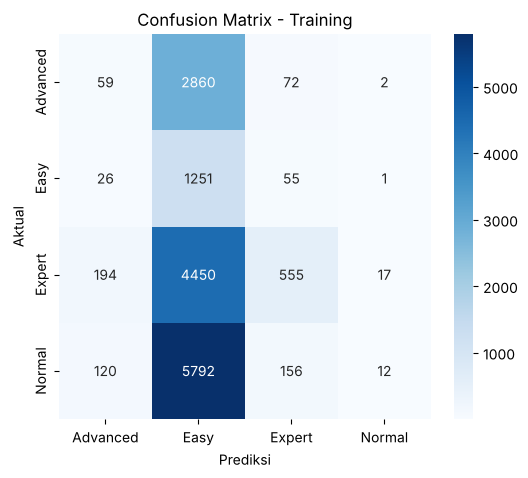

In [13]:
# 202431052_Anfal Ridho Hanif
labels = le.classes_
cm_train = confusion_matrix(y_train, y_pred_train)
print('===== Evaluasi Data Latih (Training) =====')
print('Confusion Matrix:\n', cm_train)
print('\nClassification Report:\n', classification_report(y_train, y_pred_train, target_names=labels, zero_division=0))

plt.figure(figsize=(6, 5))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix - Training')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

===== Evaluasi Data Uji (Testing) =====
Confusion Matrix:
 [[  15  931   35    0]
 [   8  435   12    1]
 [  65 1514  167    6]
 [  44 1918   55    2]]

Classification Report:
               precision    recall  f1-score   support

    Advanced       0.11      0.02      0.03       981
        Easy       0.09      0.95      0.17       456
      Expert       0.62      0.10      0.17      1752
      Normal       0.22      0.00      0.00      2019

    accuracy                           0.12      5208
   macro avg       0.26      0.27      0.09      5208
weighted avg       0.32      0.12      0.08      5208



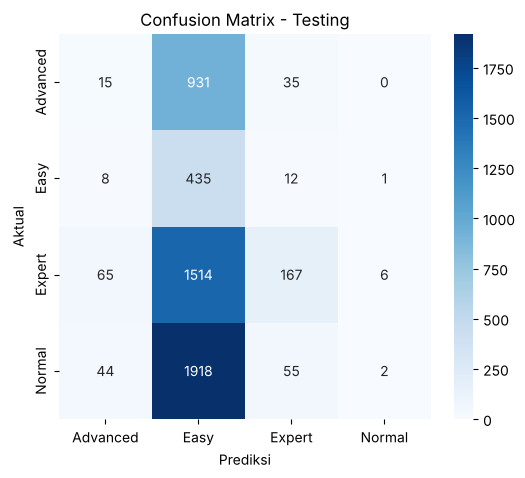

In [14]:
# 202431052_Anfal Ridho Hanif
cm_test = confusion_matrix(y_test, y_pred_test)
print('===== Evaluasi Data Uji (Testing) =====')
print('Confusion Matrix:\n', cm_test)
print('\nClassification Report:\n', classification_report(y_test, y_pred_test, target_names=labels, zero_division=0))

plt.figure(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix - Testing')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

In [15]:
# 202431052_Anfal Ridho Hanif
data_baru = x.median().to_frame().T  
data_baru['Playtime_(Hours)'] = 500
data_baru['Average_Friendly_Fire'] = 40
pred_baru = model.predict(data_baru)
print('Kode prediksi :', pred_baru[0])
print('Difficulty    :', le.inverse_transform(pred_baru)[0])

Kode prediksi : 1
Difficulty    : Easy
